In [1]:
import numpy as np
import os 
import h5py
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.signal import savgol_filter
from sklearn.preprocessing import MinMaxScaler
import warnings
from scipy import stats
import seaborn as sns
import scipy.ndimage
import scipy.stats as stats
from scipy.ndimage import gaussian_filter1d
from scipy.stats import ranksums
from numba import jit
import matplotlib as mpl
import random
import pickle
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import CalibratedClassifierCV
from typing import List, Tuple, Dict, Literal
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA

mpl.rcParams['axes.spines.right'] = False
mpl.rcParams['axes.spines.top'] = False

import gzip
import sys

# Add the folder containing your modules to the path
folder_path = '/Users/akhilbandi/Documents/Portfolio/code_projects/Context Paper Code'  # Replace with actual path
sys.path.insert(0, folder_path)

from avc_analysis import *
analysis = avc_analysis()
plotter = avc_plotting()

from data_loading import *

loader = DataLoader()  

#figures_dir = 

from matplotlib import rcParams

# Set publication style
rcParams['font.family'] = 'Arial'

# Load data 

In [2]:
mouse_ID = 'KO-5-1L' 
date = '2026-03-05'

In [3]:
save_path = f'/Volumes/Akhil Data/Akhil/ProcessedData/{mouse_ID}/{date}/glm_data_dict.pkl.gz'
with gzip.open(save_path, 'rb') as f:
    glm_data_dict = pickle.load(f)

In [4]:
trial_num = 6

In [5]:
glm_data_dict[trial_num].keys()

dict_keys(['trial_id', 'context', 'choice', 'outcome', 'trial_type', 'Visual_Stim', 'Audio_Stim', 'neural', 'movement', 'events'])

In [6]:
glm_data_dict[trial_num]['context'], glm_data_dict[trial_num]['Visual_Stim'], glm_data_dict[trial_num]['Audio_Stim'], glm_data_dict[trial_num]['choice'], glm_data_dict[trial_num]['outcome']

(2, nan, 1.0, 1, 1)

In [7]:
glm_data_dict[trial_num]['events']

{'sound_onset': 12, 'iti_start': 202, 'trial_length': 283}

# Create predictor matrix 

In [8]:
def create_cosine_bumps(x, centers, widths):
    """
    Create raised cosine bumps (matching Harvey Lab tutorial).
    
    Parameters
    ----------
    x : ndarray, shape (n_samples,)
        Positions/times to evaluate bumps at
    centers : ndarray, shape (n_bumps,)
        Center positions of each bump
    widths : ndarray, shape (n_bumps,)
        Width of each bump
        
    Returns
    -------
    bases : ndarray, shape (n_samples, n_bumps)
        Evaluated basis functions
    """
    assert centers.shape == widths.shape, "Centers and widths must have same shape"
    x_reshape = np.asarray(x).reshape(-1)
    bases = np.zeros((x_reshape.shape[0], centers.shape[0]))
    
    for idx, cent in enumerate(centers):
        w = widths[idx]
        bases[:, idx] = (np.cos(2 * np.pi * (x_reshape - cent) / w) * 0.5 + 0.5) * \
                        (np.abs(x_reshape - cent) < w / 2)
    
    return bases

In [9]:
class GLMPredictorBuilder:
    """
    GLM predictor builder.
    
    Position-dependent (0-500):
    - Position-only: 10 bumps
    - Visual context × Pos: 20 (context mean × 10 + stim contrast × 10)
      * visual_context_pos: active on ALL visual trials (sum coding)
      * visual_stim_pos: +pos on 0deg, -pos on 90deg (contrast coding)
    - Audio context × Pos: 20 (context mean × 10 + stim contrast × 10, starts at y=50)
      * audio_context_pos: active on ALL audio trials (sum coding)
      * audio_stim_pos: +pos for left(-90), -pos for right(90) (contrast coding)
    - Choice place fields: 60 (2 directions × 30, truncated at turn)
    - Velocity × Pos: 20 (4 directions × 5)

    Congruent trials (context 0): both visual_context_pos AND audio_context_pos
    are simultaneously active, allowing the GLM to separate shared context signals.

    Temporally-dependent:
    - Turn onset: 8 (2 directions × 4 forward only, choice-specific)
    - Reward/ITI: 8 (4 back + 4 forward)
    
    Total: 147 predictors (146 + constant)
    """
    
    def __init__(
        self,
        sampling_rate=15.6,
        # Position parameters
        n_pos_bases=10,
        stem_y_max=500.0,
        pos_bump_width_ratio=4.0,
        audio_start_position=50.0,
        # Velocity
        n_vel_bases=5,
        # Spatial choice
        n_place_fields=30,
        # Temporal parameters
        n_turn_bases=4,  # Per direction, forward only
        turn_window=1.0,
        n_reward_bases=8,
        reward_window=2.0,
        temporal_bump_width_ratio=4.0,
        # Event derivation
        outcome_offset_from_iti=0,
        turn_y_thresh=505.0,
        turn_x_vel_thresh=20.0,
        visual_y_thresh=500.0,
        # Modular inclusion flags
        include_position_only=True,
        include_sound_position=True,
        include_visual_position=True,
        include_velocity=True,
        include_spatial_choice=True,
        include_turn_onset=True,
        include_reward=True,
    ):
        self.sampling_rate = sampling_rate
        
        # Position
        self.n_pos_bases = n_pos_bases
        self.stem_y_max = stem_y_max
        self.pos_bump_width_ratio = pos_bump_width_ratio
        self.audio_start_position = audio_start_position
        
        # Velocity
        self.n_vel_bases = n_vel_bases
        
        # Spatial choice
        self.n_place_fields = n_place_fields
        
        # Temporal
        self.n_turn_bases = n_turn_bases
        self.turn_window = turn_window
        self.n_reward_bases = n_reward_bases
        self.reward_window = reward_window
        self.temporal_bump_width_ratio = temporal_bump_width_ratio
        
        # Event derivation
        self.outcome_offset_from_iti = outcome_offset_from_iti
        self.turn_y_thresh = turn_y_thresh
        self.turn_x_vel_thresh = turn_x_vel_thresh
        self.visual_y_thresh = visual_y_thresh
        
        # Inclusion flags
        self.include_position_only = include_position_only
        self.include_sound_position = include_sound_position
        self.include_visual_position = include_visual_position
        self.include_velocity = include_velocity
        self.include_spatial_choice = include_spatial_choice
        self.include_turn_onset = include_turn_onset
        self.include_reward = include_reward
    
    def _derive_events(self, trial, movement):
        """Derive missing event timings from trial and movement data."""
        events = trial.get("events", {}).copy()
        
        # Choice frame
        if "choice_frame" not in events:
            iti_start = events.get("iti_start")
            if iti_start is not None and iti_start > 0:
                events["choice_frame"] = iti_start - 1
        
        # Reward frame (at ITI start + offset)
        if "reward_frame" not in events:
            iti_start = events.get("iti_start")
            if iti_start is not None:
                events["reward_frame"] = iti_start + self.outcome_offset_from_iti
        
        # Turn onset frame (choice-aware)
        if "turn_onset" not in events:
            y_pos = np.asarray(movement.get("y_position", [])).flatten()
            x_vel = np.asarray(movement.get("x_velocity", [])).flatten()
            choice = trial.get("choice", 0)
            
            turn_frame = None
            for i in range(len(y_pos)):
                if y_pos[i] > self.turn_y_thresh:
                    if i > 0:
                        # Left turn: negative velocity
                        if choice == 0 and x_vel[i] < -self.turn_x_vel_thresh:
                            turn_frame = i
                            break
                        # Right turn: positive velocity
                        elif choice == 1 and x_vel[i] > self.turn_x_vel_thresh:
                            turn_frame = i
                            break
            
            if turn_frame is not None:
                events["turn_onset"] = turn_frame
        
        return events
    
    def _get_y500_frame(self, movement):
        """Get frame where y_position crosses 500."""
        y_pos = np.asarray(movement.get("y_position", [])).flatten()
        for i, y in enumerate(y_pos):
            if y > self.visual_y_thresh:
                return i
        return len(y_pos)
    
    def _get_audio_start_frame(self, movement):
        """Get frame where y_position crosses audio_start_position (50)."""
        y_pos = np.asarray(movement.get("y_position", [])).flatten()
        for i, y in enumerate(y_pos):
            if y >= self.audio_start_position:
                return i
        return 0
    
    def _build_position_bases(self, movement, n_frames):
        """Build position basis functions (raised cosine along stem 0-500)."""
        y_pos = np.asarray(movement["y_position"]).flatten()
        if y_pos.size < n_frames:
            y_pos = np.pad(y_pos, (0, n_frames - y_pos.size), constant_values=np.nan)
        
        x = y_pos[:n_frames].astype(float)
        n_b = self.n_pos_bases
        stem = self.stem_y_max
        
        if n_b == 1:
            centers = np.array([stem / 2])
            widths = np.array([stem])
        else:
            centers = np.linspace(0, stem, n_b)
            spacing = stem / (n_b - 1)
            widths = np.full(n_b, spacing * self.pos_bump_width_ratio)
        
        bases = create_cosine_bumps(x, centers, widths)
        bases = np.nan_to_num(bases, nan=0.0, posinf=0.0, neginf=0.0)
        
        names = [f"pos_bump_{i+1}" for i in range(n_b)]
        return bases, names
    
    def _build_velocity_bases(self, movement, n_frames):
        """Build velocity basis functions (5 bumps along stem 0-500)."""
        y_pos = np.asarray(movement["y_position"]).flatten()
        if y_pos.size < n_frames:
            y_pos = np.pad(y_pos, (0, n_frames - y_pos.size), constant_values=np.nan)
        
        x = y_pos[:n_frames].astype(float)
        n_b = self.n_vel_bases
        stem = self.stem_y_max
        
        if n_b == 1:
            centers = np.array([stem / 2])
            widths = np.array([stem])
        else:
            centers = np.linspace(0, stem, n_b)
            spacing = stem / (n_b - 1)
            widths = np.full(n_b, spacing * self.pos_bump_width_ratio)
        
        bases = create_cosine_bumps(x, centers, widths)
        bases = np.nan_to_num(bases, nan=0.0, posinf=0.0, neginf=0.0)
        
        return bases
    
    def _build_position_only_trial(self, pos_bases):
        """Position-only (trialPhase) predictors."""
        names = [f"trialPhase_pos{i+1}" for i in range(pos_bases.shape[1])]
        return pos_bases.copy(), names
    
    def _build_sound_position_trial(self, n_frames, audio_start_frame, audio_stim, stim_end_frame, pos_bases):
        """Audio context × position predictors (starts at y=50, ends at y=500).

        Columns [0:n_b]   audio_context_pos: active on ALL audio trials (context mean).
        Columns [n_b:2*n_b] audio_stim_pos: +pos for left(-90), -pos for right(90) (contrast).

        On congruent trials this group is active simultaneously with the visual group,
        allowing the GLM to estimate independent audio-context spatial tuning.
        """
        n_b = pos_bases.shape[1]
        pred = np.zeros((n_frames, 2 * n_b))
        names = [f"audio_context_pos{i+1}" for i in range(n_b)] + \
                [f"audio_stim_pos{i+1}" for i in range(n_b)]
        
        if np.isnan(audio_stim):
            return pred, names
        
        end_f = min(stim_end_frame, n_frames)
        if audio_start_frame >= end_f:
            return pred, names
        
        boxcar = np.zeros(n_frames)
        boxcar[audio_start_frame:end_f] = 1.0
        
        # Context mean: +1 on all audio trials
        pred[:, :n_b] = boxcar[:, None] * pos_bases
        
        # Stimulus contrast: +1 for left(-90), -1 for right(90)
        stim_sign = +1.0 if int(audio_stim) == 0 else -1.0
        pred[:, n_b:] = boxcar[:, None] * pos_bases * stim_sign
        
        return pred, names
    
    def _build_visual_position_trial(self, n_frames, stim_onset, visual_end_frame, visual_stim, pos_bases):
        """Visual context × position predictors (from sound_onset to y=500).

        Columns [0:n_b]   visual_context_pos: active on ALL visual trials (context mean).
        Columns [n_b:2*n_b] visual_stim_pos: +pos for 0deg, -pos for 90deg (contrast).

        On congruent trials this group is active simultaneously with the audio group,
        allowing the GLM to estimate independent visual-context spatial tuning.
        """
        n_b = pos_bases.shape[1]
        pred = np.zeros((n_frames, 2 * n_b))
        names = [f"visual_context_pos{i+1}" for i in range(n_b)] + \
                [f"visual_stim_pos{i+1}" for i in range(n_b)]
        
        if np.isnan(visual_stim):
            return pred, names
        
        start_f = stim_onset
        end_f = min(visual_end_frame, n_frames)
        
        if end_f <= start_f:
            return pred, names
        
        boxcar = np.zeros(n_frames)
        boxcar[start_f:end_f] = 1.0
        
        # Context mean: +1 on all visual trials
        pred[:, :n_b] = boxcar[:, None] * pos_bases
        
        # Stimulus contrast: +1 for 0deg(-90 maps to left=0deg), -1 for 90deg
        stim_sign = +1.0 if (float(visual_stim) == -90.0 or float(visual_stim) == 0.0) else -1.0
        pred[:, n_b:] = boxcar[:, None] * pos_bases * stim_sign
        
        return pred, names
    
    def _build_velocity_trial(self, movement, n_frames, vel_bases):
        """
        Velocity × position predictors.
        4 directions (forward, reverse, leftward, rightward) × 5 position bumps = 20.
        """
        n_b = self.n_vel_bases
        
        # Get velocity data
        y_vel = np.asarray(movement.get("y_velocity", [])).flatten()
        x_vel = np.asarray(movement.get("x_velocity", [])).flatten()
        
        # Pad if needed
        if y_vel.size < n_frames:
            y_vel = np.pad(y_vel, (0, n_frames - y_vel.size), constant_values=0.0)
        if x_vel.size < n_frames:
            x_vel = np.pad(x_vel, (0, n_frames - x_vel.size), constant_values=0.0)
        
        y_vel = y_vel[:n_frames]
        x_vel = x_vel[:n_frames]
        
        # Separate into directions
        forward_vel = np.maximum(y_vel, 0)
        reverse_vel = np.maximum(-y_vel, 0)
        rightward_vel = np.maximum(x_vel, 0)
        leftward_vel = np.maximum(-x_vel, 0)
        
        # Multiply by position bases
        pred = np.zeros((n_frames, 4 * n_b))
        pred[:, 0*n_b:1*n_b] = forward_vel[:, None] * vel_bases
        pred[:, 1*n_b:2*n_b] = reverse_vel[:, None] * vel_bases
        pred[:, 2*n_b:3*n_b] = rightward_vel[:, None] * vel_bases
        pred[:, 3*n_b:4*n_b] = leftward_vel[:, None] * vel_bases
        
        names = [f"vel_forward_pos{i+1}" for i in range(n_b)] + \
                [f"vel_reverse_pos{i+1}" for i in range(n_b)] + \
                [f"vel_right_pos{i+1}" for i in range(n_b)] + \
                [f"vel_left_pos{i+1}" for i in range(n_b)]
        
        return pred, names
    
    def _build_spatial_choice_trial(self, movement, n_frames, choice, turn_frame):
        """
        Spatial choice place fields (0-500, TRUNCATED at turn_onset).
        Only active BEFORE the turn is executed.
        """
        n_pf = self.n_place_fields
        stem = self.stem_y_max
        
        # Define centers and widths for place fields
        if n_pf == 1:
            centers = np.array([stem / 2])
            widths = np.array([stem])
        else:
            centers = np.linspace(0, stem, n_pf)
            spacing = stem / (n_pf - 1)
            widths = np.full(n_pf, spacing * self.pos_bump_width_ratio)
        
        # Get y position
        y_pos = np.asarray(movement["y_position"]).flatten()
        if y_pos.size < n_frames:
            y_pos = np.pad(y_pos, (0, n_frames - y_pos.size), constant_values=np.nan)
        
        x = y_pos[:n_frames].astype(float)
        
        # Evaluate place fields
        place_bases = create_cosine_bumps(x, centers, widths)
        place_bases = np.nan_to_num(place_bases, nan=0.0)
        
        # TRUNCATE at turn onset (zero out after turn)
        if turn_frame < n_frames:
            place_bases[turn_frame:, :] = 0.0
        
        # Only activate the choice-specific channel
        pred = np.zeros((n_frames, 2 * n_pf))
        names = [f"place_left_{i+1}" for i in range(n_pf)] + \
                [f"place_right_{i+1}" for i in range(n_pf)]
        
        if choice == 0:  # Left
            pred[:, :n_pf] = place_bases
        else:  # Right
            pred[:, n_pf:] = place_bases
        
        return pred, names
    
    def _build_turn_onset_trial(self, n_frames, turn_frame, choice):
        """
        Turn onset predictors (4 forward bumps only, choice-specific).
        Left choice trials get left_turn predictors, right choice get right_turn.
        """
        n_b = self.n_turn_bases
        window_frames = int(self.turn_window * self.sampling_rate)
        
        # Forward-only centers
        if n_b == 1:
            centers = np.array([window_frames / 2])
            widths = np.array([window_frames])
        else:
            centers = np.linspace(0, window_frames, n_b)
            spacing = window_frames / (n_b - 1)
            widths = np.full(n_b, spacing * self.temporal_bump_width_ratio)
        
        # Time from turn (forward only)
        time_from_turn = np.arange(n_frames, dtype=float) - turn_frame
        time_from_turn[time_from_turn < 0] = np.nan
        
        # Evaluate temporal bases
        temporal_bases = create_cosine_bumps(time_from_turn, centers, widths)
        temporal_bases = np.nan_to_num(temporal_bases, nan=0.0)
        
        # Only activate choice-specific channel
        pred = np.zeros((n_frames, 2 * n_b))
        names = [f"turn_left_t{i+1}" for i in range(n_b)] + \
                [f"turn_right_t{i+1}" for i in range(n_b)]
        
        if choice == 0:  # Left turn
            pred[:, :n_b] = temporal_bases
        else:  # Right turn
            pred[:, n_b:] = temporal_bases
        
        return pred, names
    
    def _build_reward_trial(self, n_frames, reward_frame, outcome):
        """
        Outcome/ITI predictors — forward-only, outcome-specific.

        Parameters
        ----------
        outcome : int
            1 = correct (rewarded), 0 = error (unrewarded)

        Returns n_reward_bases * 2 columns:
            columns 0..n_b-1  : correct bases (non-zero only on correct trials)
            columns n_b..2n_b-1: error bases  (non-zero only on error trials)
        """
        n_b = self.n_reward_bases
        window_frames = int(self.reward_window * self.sampling_rate)

        # Forward-only: 0 → +window_frames (no backward bases wasted on run period)
        centers = np.linspace(0, window_frames, n_b)
        spacing = window_frames / max(n_b - 1, 1)
        widths  = np.full(n_b, spacing * self.temporal_bump_width_ratio)

        time_from_reward = np.arange(n_frames, dtype=float) - reward_frame
        temporal_bases   = create_cosine_bumps(time_from_reward, centers, widths)
        temporal_bases   = np.nan_to_num(temporal_bases, nan=0.0)

        # Outcome-specific columns (same pattern as turn_onset splits by choice)
        pred  = np.zeros((n_frames, 2 * n_b))
        names = ([f"outcome_correct_t{i+1}" for i in range(n_b)] +
                 [f"outcome_error_t{i+1}"   for i in range(n_b)])

        if outcome == 1:   # correct / rewarded
            pred[:, :n_b] = temporal_bases
        else:              # error / unrewarded
            pred[:, n_b:] = temporal_bases

        return pred, names
    
    def build_design_matrices(self, glm_data_dict):
        """
        Build design matrices for all trials.
        
        Parameters
        ----------
        glm_data_dict : dict or list
            Dictionary/list indexed by trial number
            
        Returns
        -------
        design_matrices : list of ndarray
        predictor_names : list of str
        predictor_info : dict
        """
        if isinstance(glm_data_dict, dict):
            trial_indices = sorted(glm_data_dict.keys())
        else:
            trial_indices = range(len(glm_data_dict))
        
        design_matrices = []
        all_group_parts = []
        
        for idx, trial_idx in enumerate(trial_indices):
            trial_data = glm_data_dict[trial_idx]
            
            movement = trial_data.get("movement", {})
            events_raw = trial_data.get("events", {})
            
            # Get trial length
            if "trial_length" in events_raw:
                n_frames = events_raw["trial_length"]
            else:
                neural_dict = trial_data.get("neural", {})
                if neural_dict:
                    first_metric = next(iter(neural_dict.values()))
                    n_frames = first_metric.shape[0]
                else:
                    raise ValueError(f"Trial {trial_idx} missing trial_length")
            
            # Build trial dict
            trial = {
                "trial_length": n_frames,
                "events": events_raw,
                "audio_stim": trial_data.get("Audio_Stim", np.nan),
                "visual_stim": trial_data.get("Visual_Stim", np.nan),
                "choice": trial_data.get("choice", 0),
                "outcome": trial_data.get("outcome", 0),
                "context": trial_data.get("context", -1),  # 0=congruent, 1=visual, 2=audio
            }
            
            # Derive events
            events = self._derive_events(trial, movement)
            
            # Get key frames
            stim_onset = events.get("sound_onset", 0)
            audio_start_frame = self._get_audio_start_frame(movement)
            turn_frame = events.get("turn_onset", n_frames - 1)
            reward_frame = events.get("reward_frame", n_frames - 1)
            y500_frame = self._get_y500_frame(movement)
            
            # Build position bases (10 bumps for main predictors)
            pos_bases, _ = self._build_position_bases(movement, n_frames)
            
            # Build velocity bases (5 bumps)
            vel_bases = self._build_velocity_bases(movement, n_frames) if self.include_velocity else None
            
            trial_parts = []
            
            # 1. Position-only
            if self.include_position_only:
                pred, names = self._build_position_only_trial(pos_bases)
                trial_parts.append(("position_only", pred, names))
            
            # 2. Sound × position (starts at y=50)
            if self.include_sound_position:
                pred, names = self._build_sound_position_trial(
                    n_frames, audio_start_frame, trial["audio_stim"], y500_frame, pos_bases
                )
                trial_parts.append(("sound", pred, names))
            
            # 3. Visual × position
            if self.include_visual_position:
                pred, names = self._build_visual_position_trial(
                    n_frames, stim_onset, y500_frame, trial["visual_stim"], pos_bases
                )
                trial_parts.append(("visual", pred, names))
            
            # 4. Velocity × position
            if self.include_velocity and vel_bases is not None:
                pred, names = self._build_velocity_trial(movement, n_frames, vel_bases)
                trial_parts.append(("velocity", pred, names))
            
            # 5. Spatial choice place fields (TRUNCATED at turn)
            if self.include_spatial_choice:
                pred, names = self._build_spatial_choice_trial(
                    movement, n_frames, trial["choice"], turn_frame
                )
                trial_parts.append(("choice_spatial", pred, names))
            
            # 6. Turn onset (choice-specific, 4 forward only)
            if self.include_turn_onset and turn_frame < n_frames:
                pred, names = self._build_turn_onset_trial(n_frames, turn_frame, trial["choice"])
                trial_parts.append(("turn_onset", pred, names))
            
            # 7. Outcome/ITI (forward-only, correct vs. error)
            if self.include_reward and reward_frame < n_frames:
                pred, names = self._build_reward_trial(n_frames, reward_frame, trial["outcome"])
                trial_parts.append(("outcome", pred, names))
            
            # Store metadata from first trial
            if idx == 0:
                all_group_parts = trial_parts
            
            # Concatenate
            trial_preds = [part[1] for part in trial_parts]
            design_trial = np.column_stack(trial_preds) if trial_preds else np.zeros((n_frames, 0))
            
            design_matrices.append(design_trial)
        
        # Build predictor_names and predictor_info
        predictor_names = []
        predictor_info = {}
        current_idx = 0
        
        for group_name, pred, names in all_group_parts:
            n_pred = pred.shape[1]
            predictor_info[group_name] = {
                "start": current_idx,
                "end": current_idx + n_pred,
                "names": names
            }
            predictor_names.extend(names)
            current_idx += n_pred
        
        return design_matrices, predictor_names, predictor_info
    
    def plot_predictors(self, glm_data_dict, design_matrices, predictor_info,
                       start_trial=0, n_trials=5, figsize=(24, 22),
                       neural_metric='deconv', n_example_neurons=15,
                       example_neuron_ids=None):
        """
        Plot all predictors for consecutive trials in frame-time view.
        
        Parameters
        ----------
        start_trial : int
            Starting trial index
        n_trials : int
            Number of consecutive trials to show
        neural_metric : str
            Which neural signal to overlay ('deconv', 'dff', 'z_dff')
        n_example_neurons : int
            Number of randomly sampled neurons to show (ignored if example_neuron_ids given)
        example_neuron_ids : array-like or None
            Pin specific neuron indices; if None, samples randomly with seed=42
        """
        trial_indices = list(range(start_trial, min(start_trial + n_trials, len(design_matrices))))
        n_trials = len(trial_indices)
        
        # Setup figure: rows for each predictor type + 1 neural row at bottom
        n_rows = 10 if self.include_velocity else 9
        fig, axes = plt.subplots(n_rows, 1, figsize=figsize, sharex=False)
        
        # Select example neurons once (fixed seed for reproducibility across calls)
        first_neural = glm_data_dict[trial_indices[0]].get('neural', {}).get(neural_metric)
        if first_neural is not None:
            n_neurons_total = first_neural.shape[1]
            if example_neuron_ids is None:
                rng = np.random.default_rng(seed=42)
                example_neuron_ids = np.sort(
                    rng.choice(n_neurons_total,
                               size=min(n_example_neurons, n_neurons_total),
                               replace=False)
                )
        
        # Track frame offsets for concatenation
        frame_offset = 0
        trial_boundaries = [0]
        
        for trial_idx in trial_indices:
            trial_data = glm_data_dict[trial_idx]
            design_trial = design_matrices[trial_idx]
            movement = trial_data['movement']
            events = trial_data['events']
            
            n_frames = design_trial.shape[0]
            frame_axis = np.arange(frame_offset, frame_offset + n_frames)
            frame_offset += n_frames
            trial_boundaries.append(frame_offset)
            
            # Get data
            y_pos = np.asarray(movement['y_position']).flatten()[:n_frames]
            audio_stim = trial_data.get('Audio_Stim', np.nan)
            visual_stim = trial_data.get('Visual_Stim', np.nan)
            choice = trial_data.get('choice', 0)
            outcome = trial_data.get('outcome', 0)
            
            # Event frames
            audio_start_frame = self._get_audio_start_frame(movement)
            y500_frame = self._get_y500_frame(movement)
            choice_frame = events.get('iti_start', n_frames) - 1
            reward_frame = choice_frame + self.outcome_offset_from_iti
            
            # Get turn frame
            x_vel = np.asarray(movement.get('x_velocity', [])).flatten()
            turn_frame = None
            for i in range(len(y_pos)):
                if y_pos[i] > self.turn_y_thresh:
                    if i > 0 and abs(x_vel[i]) > self.turn_x_vel_thresh:
                        turn_frame = i
                        break
            if turn_frame is None:
                turn_frame = choice_frame
            
            # Global coordinates
            audio_start_global = frame_axis[0] + audio_start_frame
            y500_global = frame_axis[0] + y500_frame if y500_frame < n_frames else frame_axis[-1]
            choice_global = frame_axis[0] + choice_frame
            reward_global = frame_axis[0] + reward_frame
            turn_global = frame_axis[0] + turn_frame
            
            row_idx = 0
            
            # --- Row: Y-position trajectory ---
            ax = axes[row_idx]
            ax.plot(frame_axis, y_pos, 'k-', linewidth=1.5, alpha=0.7)
            ax.axhline(self.audio_start_position, color='orange', linestyle=':', alpha=0.3, linewidth=1)
            ax.axhline(self.stem_y_max, color='red', linestyle=':', alpha=0.3, linewidth=1)
            row_idx += 1
            
            # --- Row: Sound boxcar (raw) ---
            ax = axes[row_idx]
            if not np.isnan(audio_stim):
                boxcar = np.zeros(n_frames)
                if audio_start_frame < y500_frame:
                    boxcar[audio_start_frame:min(y500_frame, n_frames)] = 1.0 if int(audio_stim) == 0 else -1.0
                color = 'blue' if int(audio_stim) == 0 else 'red'
                ax.fill_between(frame_axis, 0, boxcar, color=color, alpha=0.3, step='mid')
                ax.plot(frame_axis, boxcar, color=color, linewidth=2, alpha=0.8)
            row_idx += 1
            
            # --- Row: Audio context × position (expanded) ---
            # Cols [0:n_b] = audio_context_pos (gray): active on all audio trials
            # Cols [n_b:2*n_b] = audio_stim_pos (+/- signed): left=positive, right=negative
            ax = axes[row_idx]
            if 'sound' in predictor_info:
                info = predictor_info['sound']
                start, end = info['start'], info['end']
                preds = design_trial[:, start:end]
                n_b = preds.shape[1] // 2
                
                if not np.isnan(audio_stim):
                    # Context mean bumps (gray) — active on every audio trial
                    for i in range(n_b):
                        ax.plot(frame_axis, preds[:, i],
                                color=plt.cm.Greys(0.35 + 0.45 * i / max(n_b - 1, 1)),
                                alpha=0.7, linewidth=1.2)
                    # Stimulus contrast bumps: blue for left(+), red for right(-)
                    stim_color = plt.cm.Blues if int(audio_stim) == 0 else plt.cm.Reds
                    for i in range(n_b):
                        ax.plot(frame_axis, preds[:, n_b + i],
                                color=stim_color(0.3 + 0.6 * i / max(n_b - 1, 1)),
                                alpha=0.6, linewidth=1.0, linestyle='--')
            row_idx += 1
            
            # --- Row: Visual boxcar (raw) ---
            ax = axes[row_idx]
            if not np.isnan(visual_stim):
                boxcar = np.zeros(n_frames)
                boxcar[:min(y500_frame, n_frames)] = 1.0 if float(visual_stim) in [-90.0, 0.0] else -1.0
                color = 'blue' if float(visual_stim) in [-90.0, 0.0] else 'red'
                ax.fill_between(frame_axis, 0, boxcar, color=color, alpha=0.3, step='mid')
                ax.plot(frame_axis, boxcar, color=color, linewidth=2, alpha=0.8)
            row_idx += 1
            
            # --- Row: Visual context × position (expanded) ---
            # Cols [0:n_b] = visual_context_pos (gray): active on all visual trials
            # Cols [n_b:2*n_b] = visual_stim_pos (+/- signed): 0deg=positive, 90deg=negative
            ax = axes[row_idx]
            if 'visual' in predictor_info:
                info = predictor_info['visual']
                start, end = info['start'], info['end']
                preds = design_trial[:, start:end]
                n_b = preds.shape[1] // 2
                
                if not np.isnan(visual_stim):
                    # Context mean bumps (gray) — active on every visual trial
                    for i in range(n_b):
                        ax.plot(frame_axis, preds[:, i],
                                color=plt.cm.Greys(0.35 + 0.45 * i / max(n_b - 1, 1)),
                                alpha=0.7, linewidth=1.2)
                    # Stimulus contrast bumps: blue for 0deg(+), red for 90deg(-)
                    stim_color = plt.cm.Blues if float(visual_stim) in [-90.0, 0.0] else plt.cm.Reds
                    for i in range(n_b):
                        ax.plot(frame_axis, preds[:, n_b + i],
                                color=stim_color(0.3 + 0.6 * i / max(n_b - 1, 1)),
                                alpha=0.6, linewidth=1.0, linestyle='--')
            row_idx += 1
            
            # --- Row: Velocity × position (if included) ---
            if self.include_velocity:
                ax = axes[row_idx]
                if 'velocity' in predictor_info:
                    info = predictor_info['velocity']
                    start, end = info['start'], info['end']
                    preds = design_trial[:, start:end]
                    n_b = preds.shape[1] // 4
                    
                    # Plot each direction with different color
                    for i in range(n_b):
                        ax.plot(frame_axis, preds[:, 0*n_b + i], color=plt.cm.Blues(0.4 + 0.5*i/(n_b-1)), 
                               alpha=0.5, linewidth=0.8)
                        ax.plot(frame_axis, preds[:, 1*n_b + i], color=plt.cm.Reds(0.4 + 0.5*i/(n_b-1)), 
                               alpha=0.5, linewidth=0.8)
                        ax.plot(frame_axis, preds[:, 2*n_b + i], color=plt.cm.Purples(0.4 + 0.5*i/(n_b-1)), 
                               alpha=0.5, linewidth=0.8)
                        ax.plot(frame_axis, preds[:, 3*n_b + i], color=plt.cm.Greens(0.4 + 0.5*i/(n_b-1)), 
                               alpha=0.5, linewidth=0.8)
                row_idx += 1
            
            # --- Row: Choice indicator (raw) ---
            ax = axes[row_idx]
            choice_line = np.ones(n_frames) * (1.0 if choice == 0 else -1.0)
            color = 'green' if choice == 0 else 'purple'
            ax.fill_between(frame_axis, 0, choice_line, color=color, alpha=0.3, step='mid')
            ax.plot(frame_axis, choice_line, color=color, linewidth=2, alpha=0.8)
            ax.axvline(choice_global, color=color, linestyle='--', alpha=0.7, linewidth=1.5)
            row_idx += 1
            
            # --- Row: Choice place fields (expanded, TRUNCATED at turn) ---
            ax = axes[row_idx]
            if 'choice_spatial' in predictor_info:
                info = predictor_info['choice_spatial']
                start, end = info['start'], info['end']
                preds = design_trial[:, start:end]
                n_pf = preds.shape[1] // 2
                
                if choice == 0:
                    for i in range(n_pf):
                        ax.plot(frame_axis, preds[:, i], color=plt.cm.Greens(0.3 + 0.6*i/(n_pf-1)), 
                               alpha=0.4, linewidth=0.6)
                else:
                    for i in range(n_pf):
                        ax.plot(frame_axis, preds[:, n_pf + i], color=plt.cm.Purples(0.3 + 0.6*i/(n_pf-1)), 
                               alpha=0.4, linewidth=0.6)
                # Mark turn onset (where truncation happens)
                ax.axvline(turn_global, color='orange', linestyle=':', alpha=0.5, linewidth=2)
            row_idx += 1
            
            # --- Row: Turn & Reward events (temporal) ---
            ax = axes[row_idx]
            # Turn (choice-specific)
            if 'turn_onset' in predictor_info:
                info = predictor_info['turn_onset']
                start, end = info['start'], info['end']
                preds = design_trial[:, start:end]
                n_b = preds.shape[1] // 2
                
                if choice == 0:
                    for i in range(n_b):
                        ax.plot(frame_axis, preds[:, i], color=plt.cm.Greens(0.4 + 0.5*i/(n_b-1)), 
                               alpha=0.6, linewidth=1.0)
                else:
                    for i in range(n_b):
                        ax.plot(frame_axis, preds[:, n_b + i], color=plt.cm.Purples(0.4 + 0.5*i/(n_b-1)), 
                               alpha=0.6, linewidth=1.0)
                ax.axvline(turn_global, color='orange', linestyle='--', alpha=0.7, linewidth=2)
            
            # Outcome/ITI (forward-only, correct=green, error=red)
            if 'outcome' in predictor_info:
                info = predictor_info['outcome']
                start, end = info['start'], info['end']
                preds = design_trial[:, start:end]
                n_b = preds.shape[1] // 2  # first half=correct, second half=error
                for i in range(n_b):
                    ax.plot(frame_axis, preds[:, i], color=plt.cm.Greens(0.4 + 0.5*i/(max(n_b-1,1))),
                            alpha=0.7, linewidth=0.9, linestyle='--')
                for i in range(n_b):
                    ax.plot(frame_axis, preds[:, n_b + i], color=plt.cm.Reds(0.4 + 0.5*i/(max(n_b-1,1))),
                            alpha=0.7, linewidth=0.9, linestyle=':')
                ax.axvline(reward_global, color='green', linestyle='--', alpha=0.7, linewidth=2)
            row_idx += 1
            
            # --- Row: Deconvolved neural activity (example neurons, stacked traces) ---
            ax = axes[row_idx]
            neural_data = trial_data.get('neural', {}).get(neural_metric)
            if neural_data is not None and example_neuron_ids is not None:
                traces = np.asarray(neural_data)[:n_frames, :][:, example_neuron_ids]
                n_shown = traces.shape[1]
                trace_std = traces.std(axis=0)
                trace_mean = traces.mean(axis=0)
                traces_z = (traces - trace_mean) / (trace_std + 1e-8)
                spacing = 3.0
                for j in range(n_shown):
                    offset = j * spacing
                    ax.plot(frame_axis, traces_z[:, j] + offset,
                            linewidth=0.8, alpha=0.85,
                            color='black')
                ax.set_ylim(-spacing, n_shown * spacing)
        
        # Draw trial boundaries
        for boundary in trial_boundaries[1:-1]:
            for ax in axes:
                ax.axvline(boundary, color='black', linestyle='-', alpha=0.3, linewidth=2, zorder=100)
        
        # Labels
        row_idx = 0
        axes[row_idx].set_ylabel('Y Position', fontsize=11, fontweight='bold')
        axes[row_idx].set_title(f'Predictors: {n_trials} Consecutive Trials (T{trial_indices[0]}-T{trial_indices[-1]})', 
                         fontsize=13, fontweight='bold')
        row_idx += 1
        
        axes[row_idx].set_ylabel('Audio\n(raw)', fontsize=11, fontweight='bold')
        axes[row_idx].set_ylim(-1.2, 1.2)
        axes[row_idx].axhline(0, color='gray', linestyle='-', alpha=0.3, linewidth=1)
        row_idx += 1
        
        axes[row_idx].set_ylabel('Audio Ctx × Pos\n(gray=ctx, dash=stim)', fontsize=11, fontweight='bold')
        row_idx += 1
        
        axes[row_idx].set_ylabel('Visual\n(raw)', fontsize=11, fontweight='bold')
        axes[row_idx].set_ylim(-1.2, 1.2)
        axes[row_idx].axhline(0, color='gray', linestyle='-', alpha=0.3, linewidth=1)
        row_idx += 1
        
        axes[row_idx].set_ylabel('Visual Ctx × Pos\n(gray=ctx, dash=stim)', fontsize=11, fontweight='bold')
        row_idx += 1
        
        if self.include_velocity:
            axes[row_idx].set_ylabel('Velocity × Pos\n(expanded)', fontsize=11, fontweight='bold')
            axes[row_idx].text(0.98, 0.95, 'Blue=Fwd, Red=Rev, Purple=Right, Green=Left', 
                              transform=axes[row_idx].transAxes, fontsize=8, ha='right',
                              bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))
            row_idx += 1
        
        axes[row_idx].set_ylabel('Choice\n(raw)', fontsize=11, fontweight='bold')
        axes[row_idx].set_ylim(-1.2, 1.2)
        axes[row_idx].axhline(0, color='gray', linestyle='-', alpha=0.3, linewidth=1)
        row_idx += 1
        
        axes[row_idx].set_ylabel('Choice Fields\n(→turn)', fontsize=11, fontweight='bold')
        row_idx += 1
        
        axes[row_idx].set_ylabel('Turn + Outcome\n(temporal)', fontsize=11, fontweight='bold')
        axes[row_idx].text(0.98, 0.95, 'Solid=Turn, Dash=Correct, Dot=Error', 
                          transform=axes[row_idx].transAxes, fontsize=8, ha='right',
                          bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))
        row_idx += 1
        
        n_shown_label = len(example_neuron_ids) if example_neuron_ids is not None else 0
        axes[row_idx].set_ylabel(f'Neural\n({neural_metric}, n={n_shown_label})', fontsize=11, fontweight='bold')
        axes[row_idx].set_yticks([])
        axes[row_idx].set_xlabel('Frame (concatenated)', fontsize=12)
        
        # Add trial labels at top
        for i, trial_idx in enumerate(trial_indices):
            mid_frame = (trial_boundaries[i] + trial_boundaries[i+1]) / 2
            axes[0].text(mid_frame, 1.05, f'T{trial_idx}', transform=axes[0].get_xaxis_transform(),
                        ha='center', fontsize=10, fontweight='bold',
                        bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.5))
        
        # for ax in axes:
        #     ax.grid(alpha=0.3, axis='y')
        
        plt.tight_layout()
        plt.show()

Number of trials: 396
Number of predictors: 150

Predictor groups:
  position_only: 10 predictors (indices 0:10)
  sound: 20 predictors (indices 10:30)
  visual: 20 predictors (indices 30:50)
  velocity: 20 predictors (indices 50:70)
  choice_spatial: 60 predictors (indices 70:130)
  turn_onset: 8 predictors (indices 130:138)
  outcome: 12 predictors (indices 138:150)


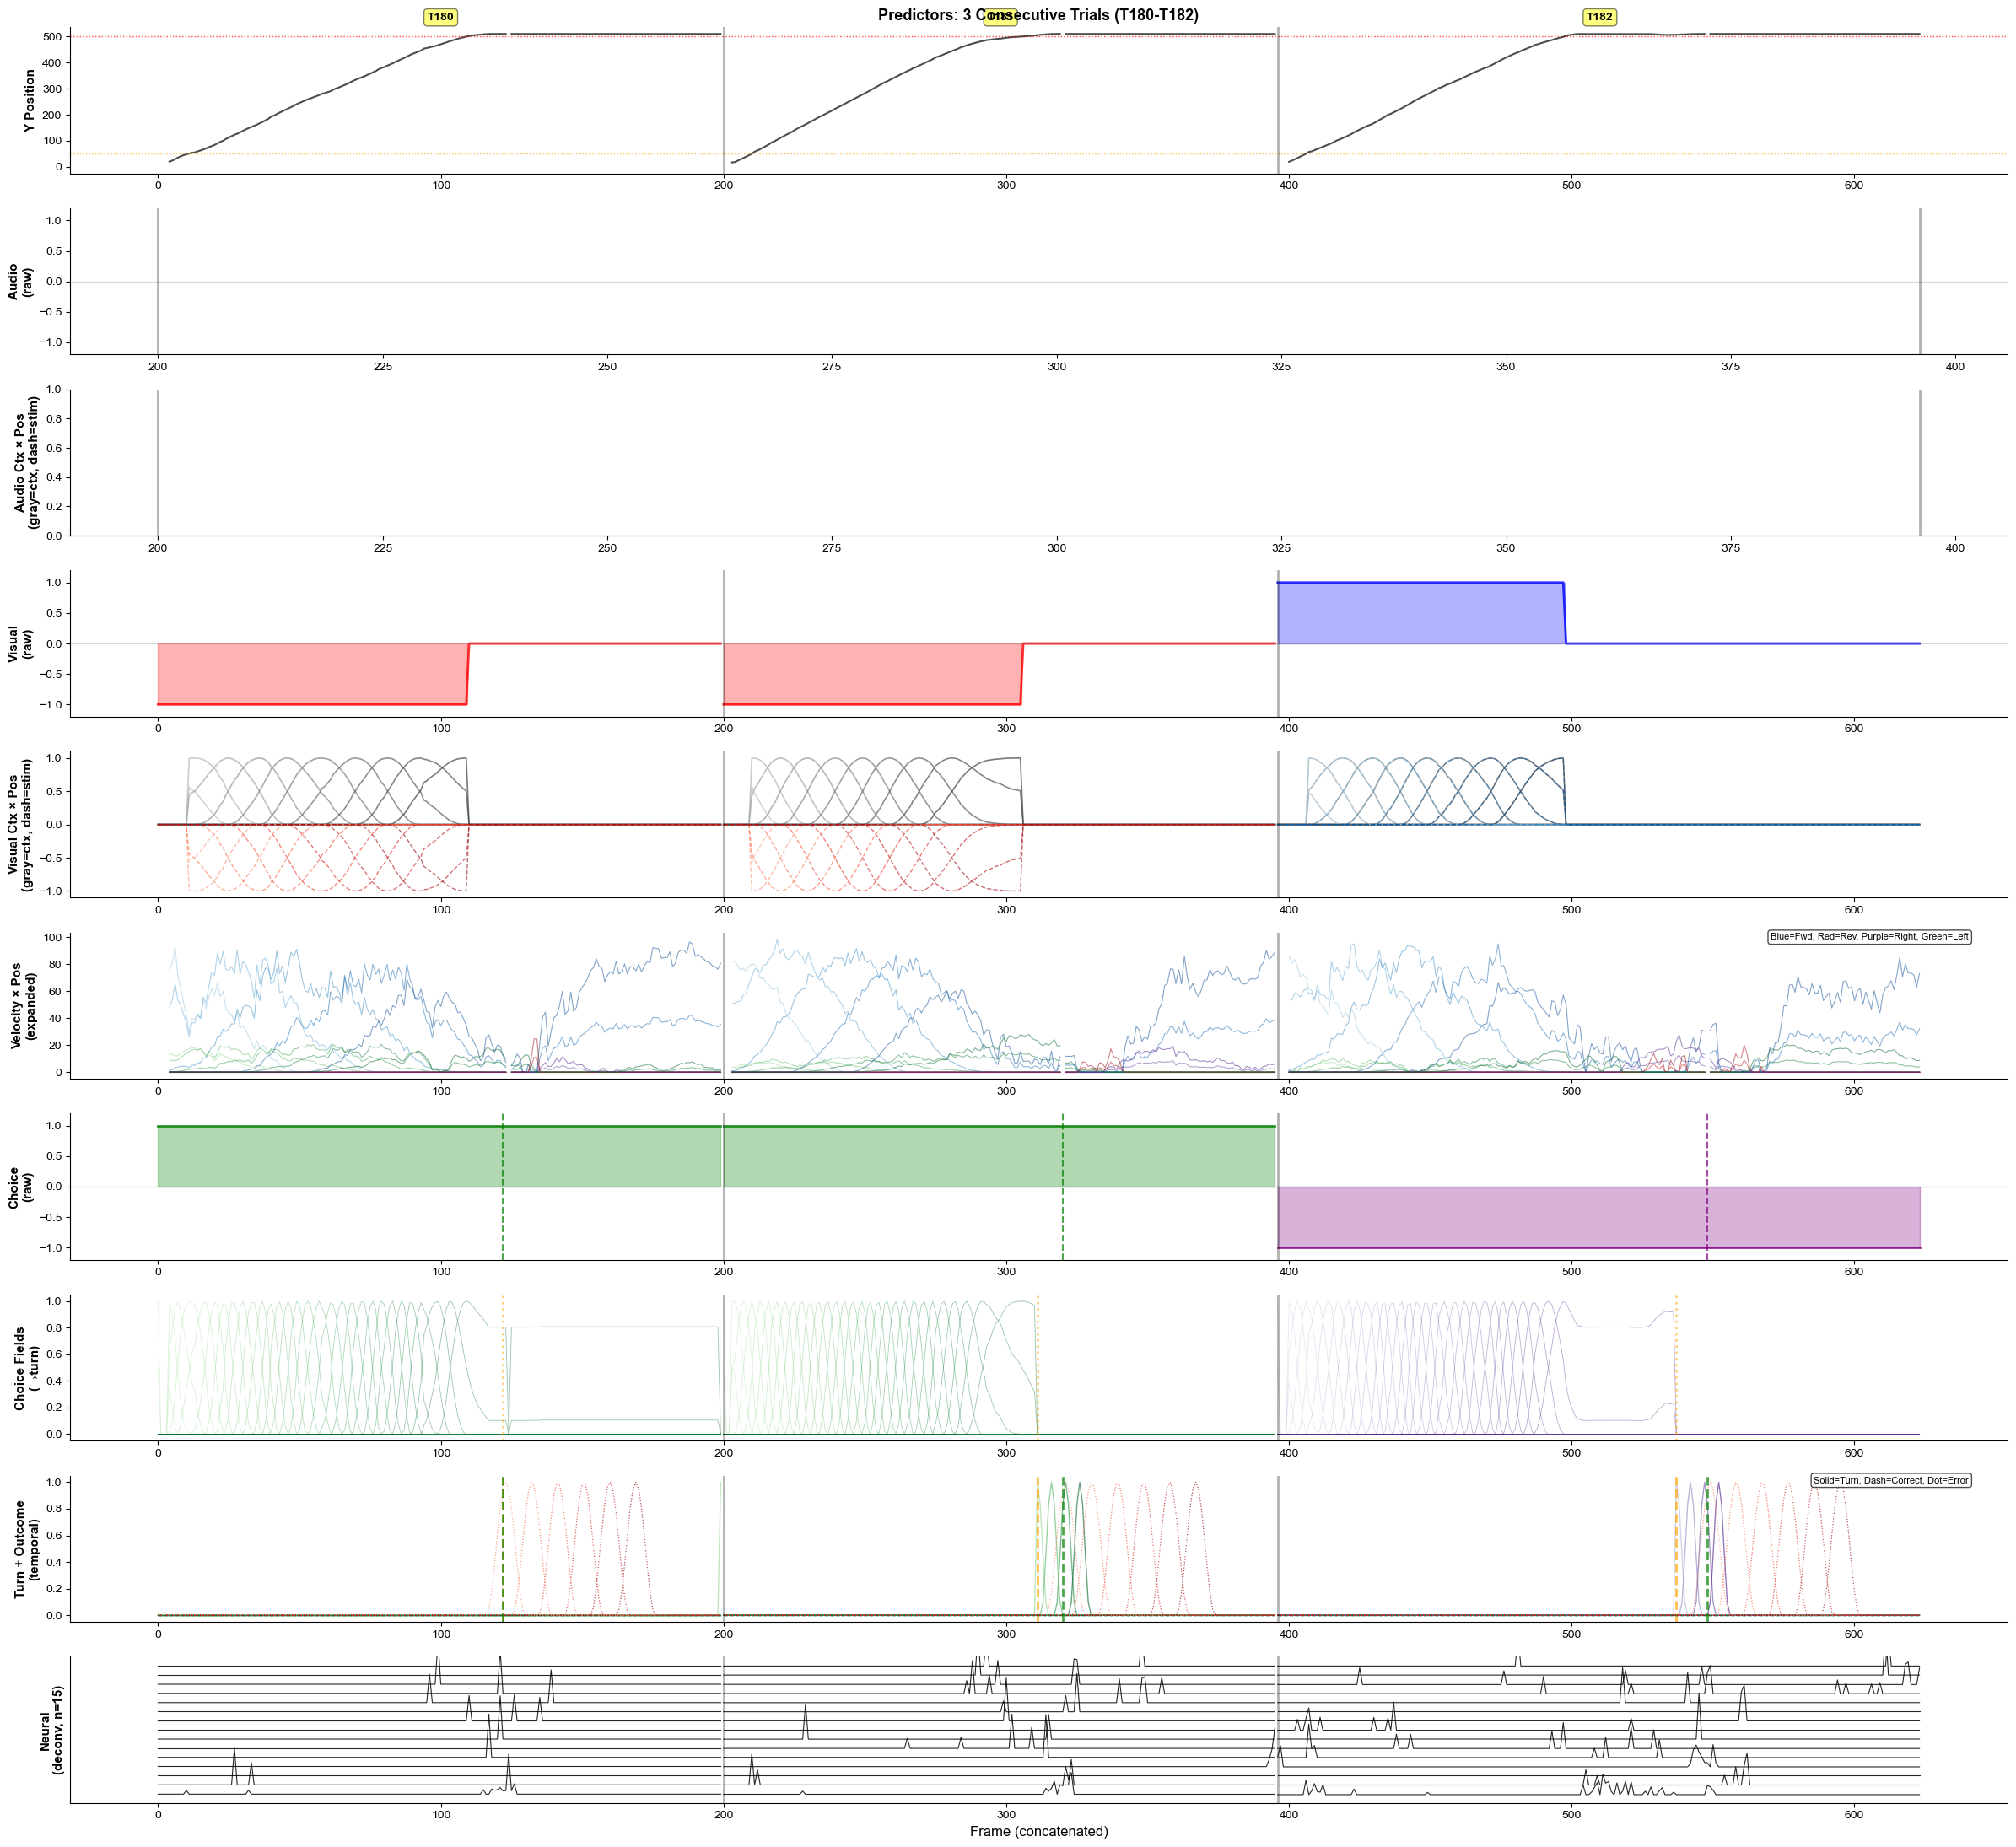

In [14]:
# Create V3 Final builder
builder = GLMPredictorBuilder(
    sampling_rate=15.6,
    n_pos_bases=10,
    stem_y_max=500.0,
    pos_bump_width_ratio=4.0,
    audio_start_position=50.0,
    n_vel_bases=5,
    n_place_fields=30,
    n_turn_bases=4,  # Per direction, forward only
    turn_window=1.0,
    n_reward_bases=6,
    reward_window=3.0,
    temporal_bump_width_ratio=1.5,  # reduced from 4.0 – prevents outcome bleed into run
    include_position_only=True,   # needed for combined-context fitting
    include_sound_position=True,
    include_visual_position=True,
    include_velocity=True,
    include_spatial_choice=True,
    include_turn_onset=True,
    include_reward=True
)

# Build design matrices
design_matrices, predictor_names, predictor_info = builder.build_design_matrices(glm_data_dict)

print(f"Number of trials: {len(design_matrices)}")
print(f"Number of predictors: {len(predictor_names)}")
print(f"\nPredictor groups:")
for group, info in predictor_info.items():
    n_pred = info["end"] - info["start"]
    print(f"  {group}: {n_pred} predictors (indices {info['start']}:{info['end']})")

# Plot first 5 trials
builder.plot_predictors(glm_data_dict, design_matrices, predictor_info, 
                                  start_trial=180, n_trials=3)

---

# Stacking for GLM Fitting

Stack per-trial design matrices and neural data into X and Y matrices, following Harvey Lab tutorial approach.

In [32]:
def stack_for_glm(glm_data_dict, design_matrices, predictor_info, neural_metric='deconv'):
    """
    Stack per-trial design matrices, neural data, and metadata for GLM fitting.
    
    Follows Harvey Lab tutorial approach:
    - Stacks all trials into single X and Y matrices
    - Z-scores X along sample dimension for even regularization
    - Removes constant predictor (becomes degenerate after z-scoring)
    - Scales Y by 10 if using deconv (to mimic spike counts)
    - Tracks frame-level metadata for balanced splitting and conditional analysis
    
    Parameters
    ----------
    glm_data_dict : dict or list
        Trial data dictionary (indexed by trial number)
    design_matrices : list of ndarray
        Per-trial design matrices from GLMPredictorBuilder
    predictor_info : dict
        Predictor group information with 'start', 'end', 'names' for each group
    neural_metric : str, default='deconv'
        Which neural metric to use ('deconv', 'dff', 'z_dff')
    
    Returns
    -------
    X : ndarray, shape (n_samples, n_predictors)
        Z-scored design matrix (all trials concatenated)
        Note: Constant predictor is removed, so n_predictors = original - 1
    Y : ndarray, shape (n_samples, n_neurons)
        Neural activity matrix (scaled by 10 if deconv)
    metadata : dict of ndarrays
        Frame-level trial information:
        - 'trial_id': which trial each frame belongs to
        - 'context': context condition (0 or 1)
        - 'choice': choice (0=left, 1=right)
        - 'outcome': outcome (0=error, 1=correct)
        - 'audio_stim': audio stimulus angle (-90, 90, or NaN)
        - 'visual_stim': visual stimulus angle (0, 90, or NaN)
        - 'trial_type': combined trial type ID
        - 'frame_in_trial': frame index within trial (0 to trial_length-1)
    group_indices : list of str
        Group name for each predictor (for group lasso regularization)
        Note: 'constant' group is excluded
    
    Example
    -------
    >>> X, Y, metadata, groups = stack_for_glm(glm_data_dict, design_matrices, predictor_info)
    >>> print(f"X: {X.shape}, Y: {Y.shape}")
    >>> print(f"Unique trials: {len(np.unique(metadata['trial_id']))}")
    >>> print(f"Outcomes: correct={np.sum(metadata['outcome']==1)}, error={np.sum(metadata['outcome']==0)}")
    """
    import scipy.stats
    
    # Determine if dict or list
    if isinstance(glm_data_dict, dict):
        trial_indices = sorted(glm_data_dict.keys())
    else:
        trial_indices = range(len(glm_data_dict))
    
    # Stack X (design matrices)
    X_raw = np.vstack(design_matrices)
    
    # Initialize lists for Y and metadata
    Y_list = []
    trial_id_list = []
    context_list = []
    choice_list = []
    outcome_list = []
    audio_stim_list = []
    visual_stim_list = []
    trial_type_list = []
    frame_in_trial_list = []
    
    # Stack Y and metadata
    for trial_idx in trial_indices:
        trial_data = glm_data_dict[trial_idx]
        
        # Neural data
        neural_dict = trial_data['neural']
        neural_data = neural_dict[neural_metric]
        n_frames = neural_data.shape[0]
        Y_list.append(neural_data)
        
        # Trial-level info (repeated for each frame)
        trial_id_list.append(np.full(n_frames, trial_idx, dtype=int))
        context_list.append(np.full(n_frames, trial_data.get('context', -1), dtype=int))
        choice_list.append(np.full(n_frames, trial_data.get('choice', -1), dtype=int))
        outcome_list.append(np.full(n_frames, trial_data.get('outcome', -1), dtype=int))
        
        # Stimulus info
        audio_stim_list.append(np.full(n_frames, trial_data.get('Audio_Stim', np.nan), dtype=float))
        visual_stim_list.append(np.full(n_frames, trial_data.get('Visual_Stim', np.nan), dtype=float))
        trial_type_list.append(np.full(n_frames, trial_data.get('trial_type', -1), dtype=int))
        
        # Frame-within-trial index
        frame_in_trial_list.append(np.arange(n_frames, dtype=int))
    
    # Concatenate all
    Y_raw = np.vstack(Y_list)
    
    metadata = {
        'trial_id': np.concatenate(trial_id_list),
        'context': np.concatenate(context_list),
        'choice': np.concatenate(choice_list),
        'outcome': np.concatenate(outcome_list),
        'audio_stim': np.concatenate(audio_stim_list),
        'visual_stim': np.concatenate(visual_stim_list),
        'trial_type': np.concatenate(trial_type_list),
        'frame_in_trial': np.concatenate(frame_in_trial_list),
    }
    
    # Z-score X along sample dimension (following Harvey Lab tutorial)
    # This ensures regularization has even effect across features
    X = scipy.stats.zscore(X_raw, axis=0, nan_policy='omit')
    X = np.nan_to_num(X, nan=0.0, posinf=0.0, neginf=0.0)
    
    # Scale Y (following Harvey Lab tutorial)
    if neural_metric == 'deconv':
        # Multiply by 10 to mimic spike counts (0.1 deconv ≈ 1 spike)
        #Y = 10.0 * Y_raw
        Y = Y_raw.copy()
    else:
        Y = Y_raw.copy()
    
    # Create group indices for regularization (now without constant)
    group_indices = []
    for group_name, info in predictor_info.items():
        n_pred = info['end'] - info['start']
        group_indices.extend([group_name] * n_pred)
    
    return X, Y, metadata, group_indices

## Usage Example - Stack Data

In [33]:
# Stack all trials into X and Y with metadata
X, Y, metadata, group_indices = stack_for_glm(
    glm_data_dict, 
    design_matrices, 
    predictor_info, 
    neural_metric='deconv'
)

print("="*60)
print("STACKED DATA SUMMARY")
print("="*60)
print(f"\nX (design matrix): {X.shape}")
print(f"  - Total frames: {X.shape[0]:,}")
print(f"  - Total predictors: {X.shape[1]} (constant predictor removed after z-scoring)")
print(f"  - X range: [{X.min():.3f}, {X.max():.3f}]")
print(f"  - X mean: {X.mean():.6f}, std: {X.std():.6f}")

print(f"\nY (neural data): {Y.shape}")
print(f"  - Total frames: {Y.shape[0]:,}")
print(f"  - Number of neurons: {Y.shape[1]}")
print(f"  - Y range: [{Y.min():.3f}, {Y.max():.3f}]")
print(f"  - Y mean: {Y.mean():.3f}, std: {Y.std():.3f}")

print(f"\nMetadata:")
print(f"  - Unique trials: {len(np.unique(metadata['trial_id']))}")
print(f"  - Frames per trial (mean): {X.shape[0] / len(np.unique(metadata['trial_id'])):.1f}")

print(f"\nTrial Balance:")
print(f"  Context 0: {np.sum(metadata['context']==0)} frames ({np.sum(metadata['context']==0)/X.shape[0]*100:.1f}%)")
print(f"  Context 1: {np.sum(metadata['context']==1)} frames ({np.sum(metadata['context']==1)/X.shape[0]*100:.1f}%)")

print(f"\n  Choice Left: {np.sum(metadata['choice']==0)} frames ({np.sum(metadata['choice']==0)/X.shape[0]*100:.1f}%)")
print(f"  Choice Right: {np.sum(metadata['choice']==1)} frames ({np.sum(metadata['choice']==1)/X.shape[0]*100:.1f}%)")

print(f"\n  Outcome Correct: {np.sum(metadata['outcome']==1)} frames ({np.sum(metadata['outcome']==1)/X.shape[0]*100:.1f}%)")
print(f"  Outcome Error: {np.sum(metadata['outcome']==0)} frames ({np.sum(metadata['outcome']==0)/X.shape[0]*100:.1f}%)")

print(f"\nPredictor Groups:")
unique_groups = []
for g in group_indices:
    if g not in unique_groups:
        unique_groups.append(g)
        count = group_indices.count(g)
        print(f"  {g}: {count} predictors")

print("="*60)

STACKED DATA SUMMARY

X (design matrix): (88045, 150)
  - Total frames: 88,045
  - Total predictors: 150 (constant predictor removed after z-scoring)
  - X range: [-12.264, 52.217]
  - X mean: 0.000000, std: 0.997802

Y (neural data): (88045, 883)
  - Total frames: 88,045
  - Number of neurons: 883
  - Y range: [0.000, 1.744]
  - Y mean: 0.001, std: 0.018

Metadata:
  - Unique trials: 396
  - Frames per trial (mean): 222.3

Trial Balance:
  Context 0: 17406 frames (19.8%)
  Context 1: 32009 frames (36.4%)

  Choice Left: 53378 frames (60.6%)
  Choice Right: 34667 frames (39.4%)

  Outcome Correct: 63837 frames (72.5%)
  Outcome Error: 24208 frames (27.5%)

Predictor Groups:
  position_only: 10 predictors
  sound: 20 predictors
  visual: 20 predictors
  velocity: 20 predictors
  choice_spatial: 60 predictors
  turn_onset: 8 predictors
  outcome: 12 predictors


## Save data 

In [34]:
import pickle

save_dir = f'/Volumes/Akhil Data/Akhil/ProcessedData/{mouse_ID}/{date}/'

# Create directory if it doesn't exist
os.makedirs(save_dir, exist_ok=True)

# Prepare data dictionary with all relevant information
glm_data = {
    # Core data matrices
    'X': X,
    'Y': Y,
    
    # Metadata (frame-level trial information)
    'metadata': metadata,
    
    # Predictor information
    'predictor_names': predictor_names,
    'predictor_info': predictor_info,
    'group_indices': group_indices,
    
    # Optional: Per-trial design matrices (for trial-specific analysis)
    'design_matrices': design_matrices,
    
    # Builder configuration (for reproducibility)
    'builder_params': {
        'sampling_rate': 15.6,
        'n_pos_bases': 10,
        'stem_y_max': 500.0,
        'pos_bump_width_ratio': 4.0,
        'audio_start_position': 50.0,
        'n_vel_bases': 5,
        'n_place_fields': 30,
        'n_turn_bases': 4,
        'turn_window': 1.0,
        'n_reward_bases': 6,
        'reward_window': 3.0,
        'temporal_bump_width_ratio': 1.5,
    },
    
    # Additional info
    'neural_metric': 'deconv',
    'mouse_ID': mouse_ID,
    'date': date,
}

# Save to pickle file
save_path = os.path.join(save_dir, 'glm_data_stacked.pkl')

print(f"Saving GLM data to: {save_path}")
print(f"Data shapes:")
print(f"  X: {X.shape}")
print(f"  Y: {Y.shape}")
print(f"  Metadata: {len(metadata)} variables, {len(metadata['trial_id'])} frames")
print(f"  Predictors: {len(predictor_names)}")
print(f"  Trials: {len(design_matrices)}")

with open(save_path, 'wb') as f:
    pickle.dump(glm_data, f, protocol=pickle.HIGHEST_PROTOCOL)

# Check file size
file_size_mb = os.path.getsize(save_path) / (1024**2)
print(f"\n✓ Saved successfully!")
print(f"  File size: {file_size_mb:.2f} MB")
print(f"  Location: {save_path}")

Saving GLM data to: /Volumes/Akhil Data/Akhil/ProcessedData/KO-5-1L/2026-03-05/glm_data_stacked.pkl
Data shapes:
  X: (88045, 150)
  Y: (88045, 883)
  Metadata: 8 variables, 88045 frames
  Predictors: 150
  Trials: 396

✓ Saved successfully!
  File size: 800.05 MB
  Location: /Volumes/Akhil Data/Akhil/ProcessedData/KO-5-1L/2026-03-05/glm_data_stacked.pkl


In [15]:
# # Load in another notebook
# with open('glm_data_stacked.pkl', 'rb') as f:
#     glm_data = pickle.load(f)

# X = glm_data['X']
# Y = glm_data['Y']
# metadata = glm_data['metadata']
# predictor_info = glm_data['predictor_info']

## Balanced Train/Test Splitting

Use metadata to create balanced splits by trial conditions.

In [15]:
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold

# Method 1: Simple GroupShuffleSplit (keeps trials together, no balancing)
print("Method 1: GroupShuffleSplit (trials kept together)")
print("-" * 60)

gss = GroupShuffleSplit(n_splits=1, train_size=0.85, random_state=42)
train_idx, test_idx = next(gss.split(X, Y, groups=metadata['trial_id']))

X_train = X[train_idx]
Y_train = Y[train_idx]
X_test = X[test_idx]
Y_test = Y[test_idx]

print(f"Train: {X_train.shape[0]:,} frames ({X_train.shape[0]/X.shape[0]*100:.1f}%)")
print(f"Test:  {X_test.shape[0]:,} frames ({X_test.shape[0]/X.shape[0]*100:.1f}%)")

# Check balance in train/test
print("\nTrain set balance:")
print(f"  Context 0: {np.sum(metadata['context'][train_idx]==0)} ({np.sum(metadata['context'][train_idx]==0)/len(train_idx)*100:.1f}%)")
print(f"  Context 1: {np.sum(metadata['context'][train_idx]==1)} ({np.sum(metadata['context'][train_idx]==1)/len(train_idx)*100:.1f}%)")
print(f"  Choice Left: {np.sum(metadata['choice'][train_idx]==0)} ({np.sum(metadata['choice'][train_idx]==0)/len(train_idx)*100:.1f}%)")
print(f"  Choice Right: {np.sum(metadata['choice'][train_idx]==1)} ({np.sum(metadata['choice'][train_idx]==1)/len(train_idx)*100:.1f}%)")
print(f"  Correct: {np.sum(metadata['outcome'][train_idx]==1)} ({np.sum(metadata['outcome'][train_idx]==1)/len(train_idx)*100:.1f}%)")
print(f"  Error: {np.sum(metadata['outcome'][train_idx]==0)} ({np.sum(metadata['outcome'][train_idx]==0)/len(train_idx)*100:.1f}%)")

print("\nTest set balance:")
print(f"  Context 0: {np.sum(metadata['context'][test_idx]==0)} ({np.sum(metadata['context'][test_idx]==0)/len(test_idx)*100:.1f}%)")
print(f"  Context 1: {np.sum(metadata['context'][test_idx]==1)} ({np.sum(metadata['context'][test_idx]==1)/len(test_idx)*100:.1f}%)")
print(f"  Choice Left: {np.sum(metadata['choice'][test_idx]==0)} ({np.sum(metadata['choice'][test_idx]==0)/len(test_idx)*100:.1f}%)")
print(f"  Choice Right: {np.sum(metadata['choice'][test_idx]==1)} ({np.sum(metadata['choice'][test_idx]==1)/len(test_idx)*100:.1f}%)")
print(f"  Correct: {np.sum(metadata['outcome'][test_idx]==1)} ({np.sum(metadata['outcome'][test_idx]==1)/len(test_idx)*100:.1f}%)")
print(f"  Error: {np.sum(metadata['outcome'][test_idx]==0)} ({np.sum(metadata['outcome'][test_idx]==0)/len(test_idx)*100:.1f}%)")

Method 1: GroupShuffleSplit (trials kept together)
------------------------------------------------------------
Train: 16,753 frames (84.6%)
Test:  3,042 frames (15.4%)

Train set balance:
  Context 0: 5528 (33.0%)
  Context 1: 6688 (39.9%)
  Choice Left: 5274 (31.5%)
  Choice Right: 11479 (68.5%)
  Correct: 10846 (64.7%)
  Error: 5907 (35.3%)

Test set balance:
  Context 0: 1130 (37.1%)
  Context 1: 1482 (48.7%)
  Choice Left: 1139 (37.4%)
  Choice Right: 1903 (62.6%)
  Correct: 1958 (64.4%)
  Error: 1084 (35.6%)


In [16]:
# Method 2: Stratified by outcome (balanced correct/error trials)
print("\n" + "="*60)
print("Method 2: StratifiedGroupKFold (balanced by outcome)")
print("-" * 60)

# Get unique trial IDs and their outcomes
trial_ids = metadata['trial_id']
unique_trials = np.unique(trial_ids)

# Create trial-level labels for stratification
trial_outcomes = []
for tid in unique_trials:
    # Get outcome for this trial (first frame, all frames have same value)
    outcome = metadata['outcome'][trial_ids == tid][0]
    trial_outcomes.append(outcome)

trial_outcomes = np.array(trial_outcomes)

print(f"Total trials: {len(unique_trials)}")
print(f"  Correct trials: {np.sum(trial_outcomes==1)} ({np.sum(trial_outcomes==1)/len(trial_outcomes)*100:.1f}%)")
print(f"  Error trials: {np.sum(trial_outcomes==0)} ({np.sum(trial_outcomes==0)/len(trial_outcomes)*100:.1f}%)")

# Create a mapping from frame index to trial outcome
frame_to_trial_outcome = np.zeros(len(trial_ids), dtype=int)
for tid, outcome in zip(unique_trials, trial_outcomes):
    frame_to_trial_outcome[trial_ids == tid] = outcome

# Use StratifiedGroupKFold (5-fold CV, but we'll just use first fold for train/test)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

# Get first split
fold_splits = list(sgkf.split(X, frame_to_trial_outcome, groups=trial_ids))
train_idx_strat, test_idx_strat = fold_splits[0]

X_train_strat = X[train_idx_strat]
Y_train_strat = Y[train_idx_strat]
X_test_strat = X[test_idx_strat]
Y_test_strat = Y[test_idx_strat]

print(f"\nTrain: {X_train_strat.shape[0]:,} frames ({X_train_strat.shape[0]/X.shape[0]*100:.1f}%)")
print(f"Test:  {X_test_strat.shape[0]:,} frames ({X_test_strat.shape[0]/X.shape[0]*100:.1f}%)")

print("\nTrain set balance:")
print(f"  Correct: {np.sum(metadata['outcome'][train_idx_strat]==1)} ({np.sum(metadata['outcome'][train_idx_strat]==1)/len(train_idx_strat)*100:.1f}%)")
print(f"  Error: {np.sum(metadata['outcome'][train_idx_strat]==0)} ({np.sum(metadata['outcome'][train_idx_strat]==0)/len(train_idx_strat)*100:.1f}%)")

print("\nTest set balance:")
print(f"  Correct: {np.sum(metadata['outcome'][test_idx_strat]==1)} ({np.sum(metadata['outcome'][test_idx_strat]==1)/len(test_idx_strat)*100:.1f}%)")
print(f"  Error: {np.sum(metadata['outcome'][test_idx_strat]==0)} ({np.sum(metadata['outcome'][test_idx_strat]==0)/len(test_idx_strat)*100:.1f}%)")

print("\n" + "="*60)


Method 2: StratifiedGroupKFold (balanced by outcome)
------------------------------------------------------------
Total trials: 89
  Correct trials: 58 (65.2%)
  Error trials: 31 (34.8%)

Train: 16,055 frames (81.1%)
Test:  3,740 frames (18.9%)

Train set balance:
  Correct: 9251 (57.6%)
  Error: 6804 (42.4%)

Test set balance:
  Correct: 3553 (95.0%)
  Error: 187 (5.0%)



## Conditional Subset Analysis

Use metadata to analyze specific trial conditions.

## Helper Function: Create Balanced Splits by Multiple Factors

In [18]:
def create_stratified_split(metadata, factors=['outcome'], n_splits=5, random_state=42):
    """
    Create stratified train/test split balanced by multiple factors.
    
    Parameters
    ----------
    metadata : dict
        Metadata dictionary from stack_for_glm
    factors : list of str
        Which factors to balance (e.g., ['outcome'], ['context', 'outcome'])
    n_splits : int
        Number of folds (returns first fold as train/test)
    random_state : int
        Random seed
    
    Returns
    -------
    train_idx : ndarray
        Indices for training set
    test_idx : ndarray
        Indices for testing set
    
    Example
    -------
    >>> train_idx, test_idx = create_stratified_split(metadata, factors=['outcome', 'context'])
    >>> X_train, Y_train = X[train_idx], Y[train_idx]
    """
    from sklearn.model_selection import StratifiedGroupKFold
    
    trial_ids = metadata['trial_id']
    unique_trials = np.unique(trial_ids)
    
    # Create combined label for each trial
    trial_labels = []
    for tid in unique_trials:
        # Get values for this trial (first frame, all frames same)
        trial_mask = trial_ids == tid
        
        # Combine factors into single label
        label_parts = []
        for factor in factors:
            val = metadata[factor][trial_mask][0]
            label_parts.append(str(val))
        
        combined_label = '_'.join(label_parts)
        trial_labels.append(combined_label)
    
    # Convert to integer codes for sklearn
    unique_labels = sorted(list(set(trial_labels)))
    label_to_int = {label: i for i, label in enumerate(unique_labels)}
    trial_label_ints = np.array([label_to_int[label] for label in trial_labels])
    
    # Create frame-level labels
    frame_labels = np.zeros(len(trial_ids), dtype=int)
    for tid, label_int in zip(unique_trials, trial_label_ints):
        frame_labels[trial_ids == tid] = label_int
    
    # Stratified split
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    splits = list(sgkf.split(np.zeros((len(frame_labels), 1)), frame_labels, groups=trial_ids))
    
    train_idx, test_idx = splits[0]
    
    # Print balance
    print(f"Stratified split by {factors}:")
    print(f"  Unique trial conditions: {len(unique_labels)}")
    for label in unique_labels:
        label_int = label_to_int[label]
        train_count = np.sum(frame_labels[train_idx] == label_int)
        test_count = np.sum(frame_labels[test_idx] == label_int)
        total_count = np.sum(frame_labels == label_int)
        print(f"    {label}: Train={train_count} ({train_count/total_count*100:.1f}%), Test={test_count} ({test_count/total_count*100:.1f}%)")
    
    return train_idx, test_idx

In [19]:
# Example: Balance by outcome × context
train_idx_multi, test_idx_multi = create_stratified_split(
    metadata, 
    factors=['outcome', 'context'],
    n_splits=5,
    random_state=42
)

X_train_multi = X[train_idx_multi]
Y_train_multi = Y[train_idx_multi]
X_test_multi = X[test_idx_multi]
Y_test_multi = Y[test_idx_multi]

print(f"\nTrain: {X_train_multi.shape[0]:,} frames")
print(f"Test:  {X_test_multi.shape[0]:,} frames")

Stratified split by ['outcome', 'context']:
  Unique trial conditions: 6
    0_0: Train=596 (100.0%), Test=0 (0.0%)
    0_1: Train=3767 (78.5%), Test=1030 (21.5%)
    0_2: Train=1598 (100.0%), Test=0 (0.0%)
    1_0: Train=4797 (79.1%), Test=1265 (20.9%)
    1_1: Train=2679 (79.4%), Test=694 (20.6%)
    1_2: Train=1984 (58.9%), Test=1385 (41.1%)

Train: 15,421 frames
Test:  4,374 frames


---

## Summary: Data Ready for GLM Fitting

### What We Have:

**1. Design Matrix (X)**
- Shape: `(n_samples, 147)` - 147 predictors (146 + constant)
- Z-scored along sample dimension
- Ready for regularized GLM fitting

**2. Neural Data (Y)**
- Shape: `(n_samples, n_neurons)`
- Scaled by 10× if using deconv (to mimic spike counts)
- Ready for Poisson GLM

**3. Metadata (frame-level)**
- `trial_id`: Which trial each frame belongs to
- `context`, `choice`, `outcome`: Trial conditions
- `audio_stim`, `visual_stim`: Stimulus information
- `trial_type`: Combined trial type ID
- `frame_in_trial`: Frame position within trial

**4. Group Indices**
- Predictor group assignments for group lasso regularization

### Train/Test Splitting Options:

1. **Simple GroupShuffleSplit** - Keeps trials together, random split
2. **StratifiedGroupKFold** - Balances by single factor (e.g., outcome)
3. **Multi-factor Stratification** - Balances by multiple factors (e.g., outcome × context)

### Next Steps for GLM Fitting:

```python
# 1. Choose split method
train_idx, test_idx = create_stratified_split(metadata, factors=['outcome'])

# 2. Split data
X_train, Y_train = X[train_idx], Y[train_idx]
X_test, Y_test = X[test_idx], Y[test_idx]
trial_id_train = metadata['trial_id'][train_idx]

# 3. Fit GLM with cross-validation (following Harvey Lab tutorial)
from nemos import glm
# ... fitting code ...

# 4. Evaluate on held-out test set
# 5. Analyze feature contributions by group
# 6. Visualize tuning curves
# 7. Conditional analysis using metadata
```